In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the cleaned merged file
df = pd.read_csv("../data/processed/south_africa_cases_vaccination_cleaned.csv")
df["date"] = pd.to_datetime(df["date"])

print("Shape:", df.shape)
print("Date range:", df["date"].min().date(), "→", df["date"].max().date())
print("\nColumns:")
print(df.columns.tolist())
df.head()

Matplotlib is building the font cache; this may take a moment.


Shape: (525, 7)
Date range: 2021-02-16 → 2022-07-25

Columns:
['date', 'total', 'daily_cases', 'people_vaccinated', 'people_fully_vaccinated', 'total_vaccinations', 'daily_vaccinations']


,date,total,daily_cases,people_vaccinated,people_fully_vaccinated,total_vaccinations,daily_vaccinations
0,2021-02-16,1494119.0,1210.0,0.0,0.0,0.0,0.0
1,2021-02-17,1496439.0,2320.0,0.0,0.0,0.0,1130.0
2,2021-02-18,1498766.0,2327.0,2260.0,2260.0,2260.0,1130.0
3,2021-02-19,1500677.0,1911.0,6524.0,6524.0,6524.0,2175.0
4,2021-02-20,1502367.0,1690.0,10414.0,10414.0,10414.0,2604.0


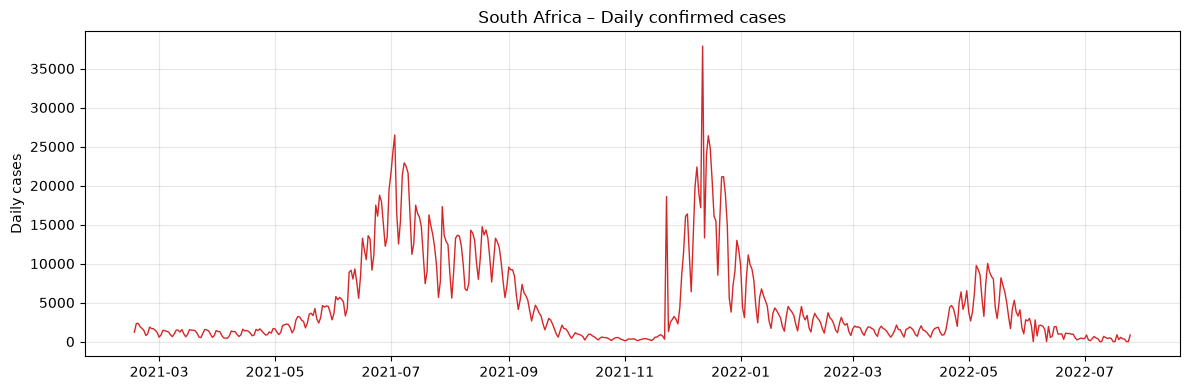

In [2]:
plt.figure(figsize=(12, 4))
plt.plot(df["date"], df["daily_cases"], color="tab:red", linewidth=1)
plt.title("South Africa – Daily confirmed cases")
plt.ylabel("Daily cases")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

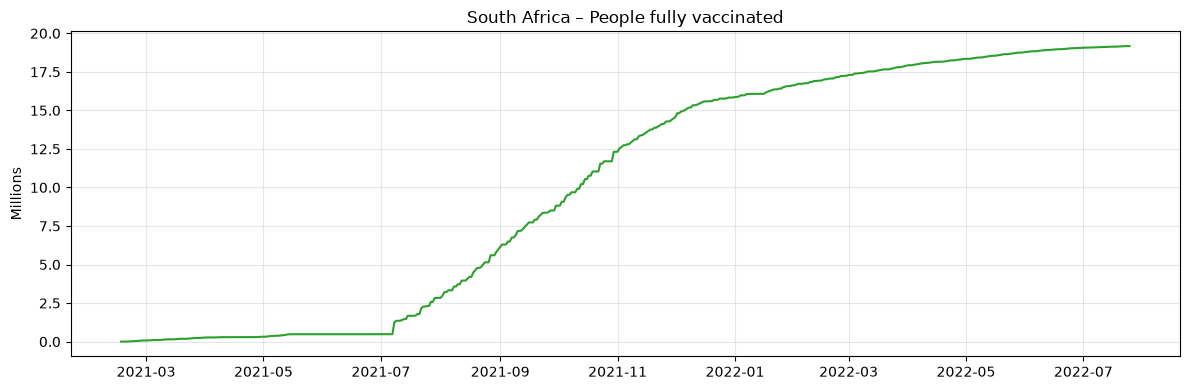

In [3]:
plt.figure(figsize=(12, 4))
plt.plot(df["date"], df["people_fully_vaccinated"] / 1e6, color="tab:green", linewidth=1.5)
plt.title("South Africa – People fully vaccinated")
plt.ylabel("Millions")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
# South Africa population (approximate, consistent with OWID)
POPULATION = 59_893_884

df["population"] = POPULATION
df["full_vax_coverage"] = df["people_fully_vaccinated"] / POPULATION
df["partial_vax_coverage"] = df["people_vaccinated"] / POPULATION

print("Max full vaccination coverage:", f"{df['full_vax_coverage'].max():.1%}")
print("Coverage at end of series:", f"{df['full_vax_coverage'].iloc[-1]:.1%}")

Max full vaccination coverage: 32.0%
Coverage at end of series: 32.0%


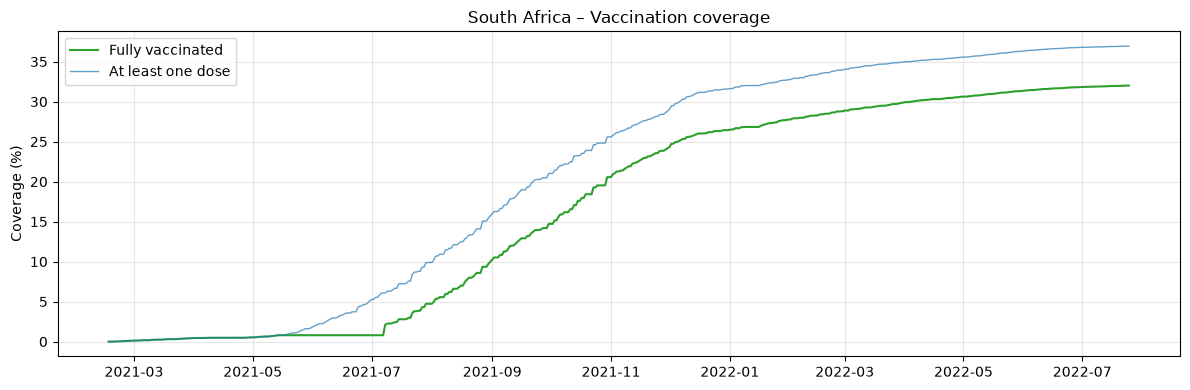

In [5]:
plt.figure(figsize=(12, 4))
plt.plot(df["date"], df["full_vax_coverage"] * 100, color="tab:green", linewidth=1.5, label="Fully vaccinated")
plt.plot(df["date"], df["partial_vax_coverage"] * 100, color="tab:blue", linewidth=1, alpha=0.7, label="At least one dose")
plt.title("South Africa – Vaccination coverage")
plt.ylabel("Coverage (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

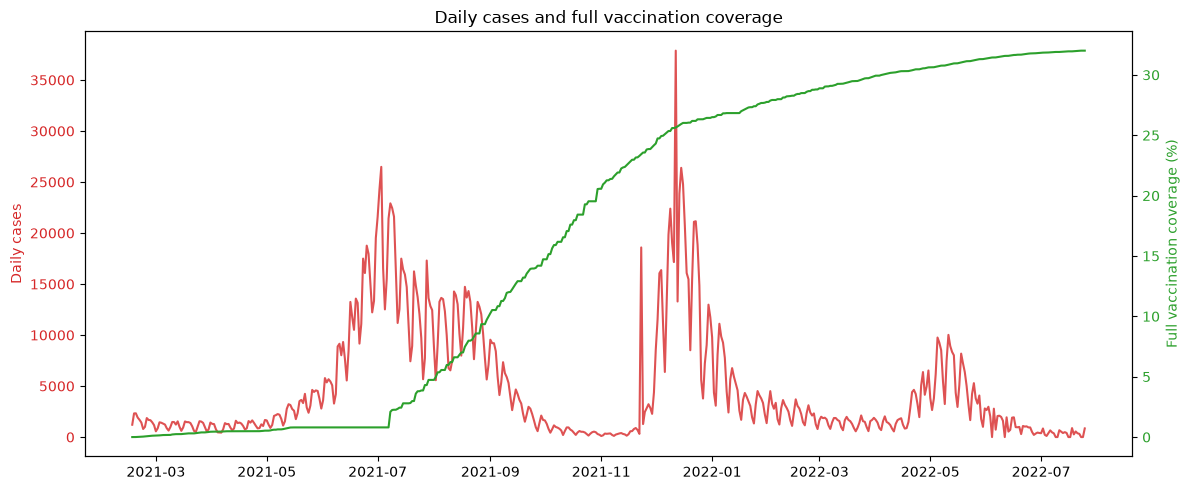

In [6]:
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(df["date"], df["daily_cases"], color="tab:red", alpha=0.8, label="Daily cases")
ax1.set_ylabel("Daily cases", color="tab:red")
ax1.tick_params(axis="y", labelcolor="tab:red")

ax2 = ax1.twinx()
ax2.plot(df["date"], df["full_vax_coverage"] * 100, color="tab:green", linewidth=1.5, label="Full vax coverage")
ax2.set_ylabel("Full vaccination coverage (%)", color="tab:green")
ax2.tick_params(axis="y", labelcolor="tab:green")

plt.title("Daily cases and full vaccination coverage")
fig.tight_layout()
plt.show()

In [7]:
df.to_csv("../data/processed/south_africa_cases_vaccination_cleaned.csv", index=False)
print("Updated file saved with coverage columns.")
print("Current columns:", df.columns.tolist())

Updated file saved with coverage columns.
Current columns: ['date', 'total', 'daily_cases', 'people_vaccinated', 'people_fully_vaccinated', 'total_vaccinations', 'daily_vaccinations', 'population', 'full_vax_coverage', 'partial_vax_coverage']


In [8]:
# Simple proxies useful for later SVIR work
df["N"] = POPULATION
df["V_approx"] = df["people_fully_vaccinated"]          # proxy for vaccinated compartment
df["cumulative_confirmed"] = df["total"]                # related to people who entered I_c pathway
df["daily_confirmed"] = df["daily_cases"]               # main observed target

# Very rough recovered proxy (confirmed minus a small fraction still active; for exploration only)
# We don't have perfect active cases, so this is approximate
df["recovered_approx"] = (df["cumulative_confirmed"] - df["daily_confirmed"].rolling(14).sum().fillna(0)).clip(lower=0)

print("New columns added.")
print(df[["date", "daily_confirmed", "V_approx", "full_vax_coverage", "recovered_approx"]].tail())

New columns added.
          date  daily_confirmed    V_approx  full_vax_coverage  \
520 2022-07-21            372.0  19156458.0           0.319840   
521 2022-07-22            317.0  19163895.0           0.319964   
522 2022-07-23              0.0  19169985.0           0.320066   
523 2022-07-24              0.0  19169985.0           0.320066   
524 2022-07-25            848.0  19169985.0           0.320066   

     recovered_approx  
520         3996904.0  
521         3997269.0  
522         3997269.0  
523         3997269.0  
524         3997939.0  


In [9]:
print("Final full vax coverage:", f"{df['full_vax_coverage'].iloc[-1]:.1%}")
print("Final cumulative confirmed:", f"{df['cumulative_confirmed'].iloc[-1]:,.0f}")
print("Final recovered approx:", f"{df['recovered_approx'].iloc[-1]:,.0f}")

Final full vax coverage: 32.0%
Final cumulative confirmed: 4,002,981
Final recovered approx: 3,997,939


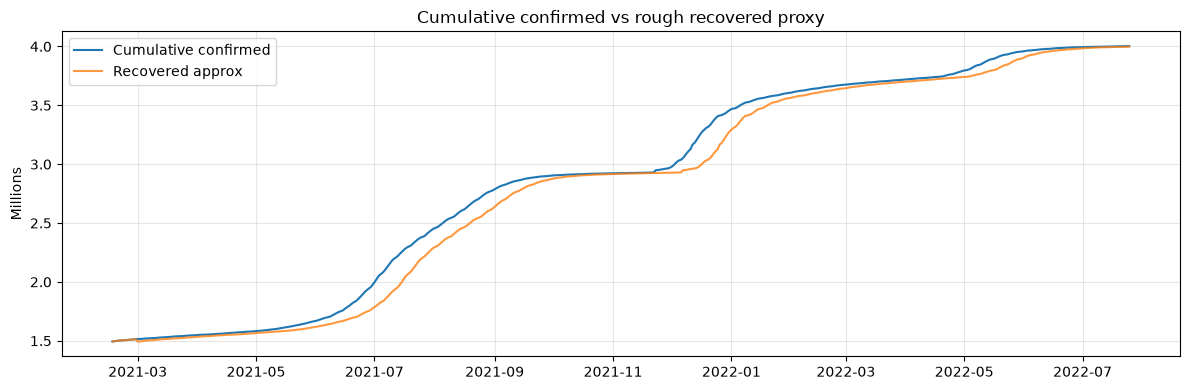

In [10]:
plt.figure(figsize=(12, 4))
plt.plot(df["date"], df["cumulative_confirmed"] / 1e6, label="Cumulative confirmed", color="tab:blue")
plt.plot(df["date"], df["recovered_approx"] / 1e6, label="Recovered approx", color="tab:orange", alpha=0.8)
plt.title("Cumulative confirmed vs rough recovered proxy")
plt.ylabel("Millions")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

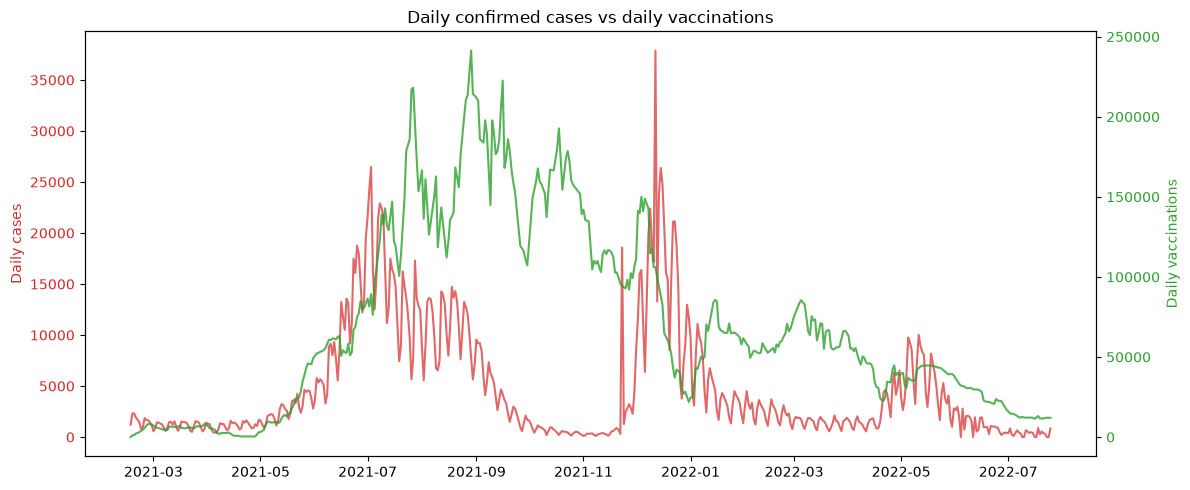

In [11]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Daily cases
ax1.plot(df["date"], df["daily_cases"], color="tab:red", alpha=0.7, label="Daily cases")
ax1.set_ylabel("Daily cases", color="tab:red")
ax1.tick_params(axis="y", labelcolor="tab:red")

# Daily vaccinations on secondary axis
ax2 = ax1.twinx()
ax2.plot(df["date"], df["daily_vaccinations"], color="tab:green", alpha=0.8, label="Daily vaccinations")
ax2.set_ylabel("Daily vaccinations", color="tab:green")
ax2.tick_params(axis="y", labelcolor="tab:green")

plt.title("Daily confirmed cases vs daily vaccinations")
fig.tight_layout()
plt.show()

In [12]:
deaths = pd.read_csv("../data/raw/covid19za_provincial_deaths.csv")

print("Shape:", deaths.shape)
print("\nColumns:")
print(deaths.columns.tolist())
print("\nFirst 5 rows:")
print(deaths.head())
print("\nLast 5 rows:")
print(deaths.tail())

Shape: (828, 14)

Columns:
['date', 'YYYYMMDD', 'EC', 'FS', 'GP', 'KZN', 'LP', 'MP', 'NC', 'NW', 'WC', 'UNKNOWN', 'total', 'source']

First 5 rows:
         date  YYYYMMDD  EC  FS  GP  KZN  LP  MP  NC  NW  WC  UNKNOWN  total  \
0  27-03-2020  20200327   0   0   0    0   0   0   0   0   1        0      1   
1  28-03-2020  20200328   0   0   0    1   0   0   0   0   1        0      2   
2  30-03-2020  20200330   0   1   0    1   0   0   0   0   1        0      3   
3  31-03-2020  20200331   0   1   1    2   0   0   0   0   1        0      5   
4  03-04-2020  20200403   0   1   1    6   0   0   0   0   1        0      9   

                                              source  
0  https://sacoronavirus.co.za/2020/03/27/latest-...  
1                                                NaN  
2                                                NaN  
3                                                NaN  
4                                                NaN  

Last 5 rows:
           date  YYYYMMDD  

In [13]:
# Parse dates
deaths["date"] = pd.to_datetime(deaths["date"], format="%d-%m-%Y")

print("Deaths date range:", deaths["date"].min().date(), "→", deaths["date"].max().date())

# Create continuous daily index matching our cases period (or full range)
full_dates = pd.date_range(start=deaths["date"].min(), 
                           end=deaths["date"].max(), 
                           freq="D")

deaths = deaths.set_index("date").reindex(full_dates)
deaths.index.name = "date"
deaths = deaths.reset_index()

# Forward-fill cumulative total
deaths["total"] = deaths["total"].ffill()

# Compute daily deaths
deaths["daily_deaths"] = deaths["total"].diff().fillna(0)

print("Shape after cleaning:", deaths.shape)
print("\nFirst few daily deaths:")
print(deaths[["date", "total", "daily_deaths"]].head(8))
print("\nLast few:")
print(deaths[["date", "total", "daily_deaths"]].tail(3))

Deaths date range: 2020-03-27 → 2022-07-25
Shape after cleaning: (851, 15)

First few daily deaths:
        date  total  daily_deaths
0 2020-03-27    1.0           0.0
1 2020-03-28    2.0           1.0
2 2020-03-29    2.0           0.0
3 2020-03-30    3.0           1.0
4 2020-03-31    5.0           2.0
5 2020-04-01    5.0           0.0
6 2020-04-02    5.0           0.0
7 2020-04-03    9.0           4.0

Last few:
          date     total  daily_deaths
848 2022-07-23  101943.0           0.0
849 2022-07-24  101943.0           0.0
850 2022-07-25  101955.0          12.0


In [14]:
# Merge daily deaths into the main dataframe
df = pd.merge(
    df,
    deaths[["date", "daily_deaths", "total"]].rename(columns={"total": "total_deaths"}),
    on="date",
    how="left"
)

# Fill any early missing daily_deaths with 0
df["daily_deaths"] = df["daily_deaths"].fillna(0)

print("Columns now:", df.columns.tolist())
print("Missing daily_deaths:", df["daily_deaths"].isna().sum())
df[["date", "daily_cases", "daily_deaths", "daily_vaccinations"]].tail()

Columns now: ['date', 'total', 'daily_cases', 'people_vaccinated', 'people_fully_vaccinated', 'total_vaccinations', 'daily_vaccinations', 'population', 'full_vax_coverage', 'partial_vax_coverage', 'N', 'V_approx', 'cumulative_confirmed', 'daily_confirmed', 'recovered_approx', 'daily_deaths', 'total_deaths']
Missing daily_deaths: 0


,date,daily_cases,daily_deaths,daily_vaccinations
520,2022-07-21,372.0,3.0,11530.0
521,2022-07-22,317.0,1.0,11918.0
522,2022-07-23,0.0,0.0,12086.0
523,2022-07-24,0.0,0.0,12056.0
524,2022-07-25,848.0,12.0,12025.0


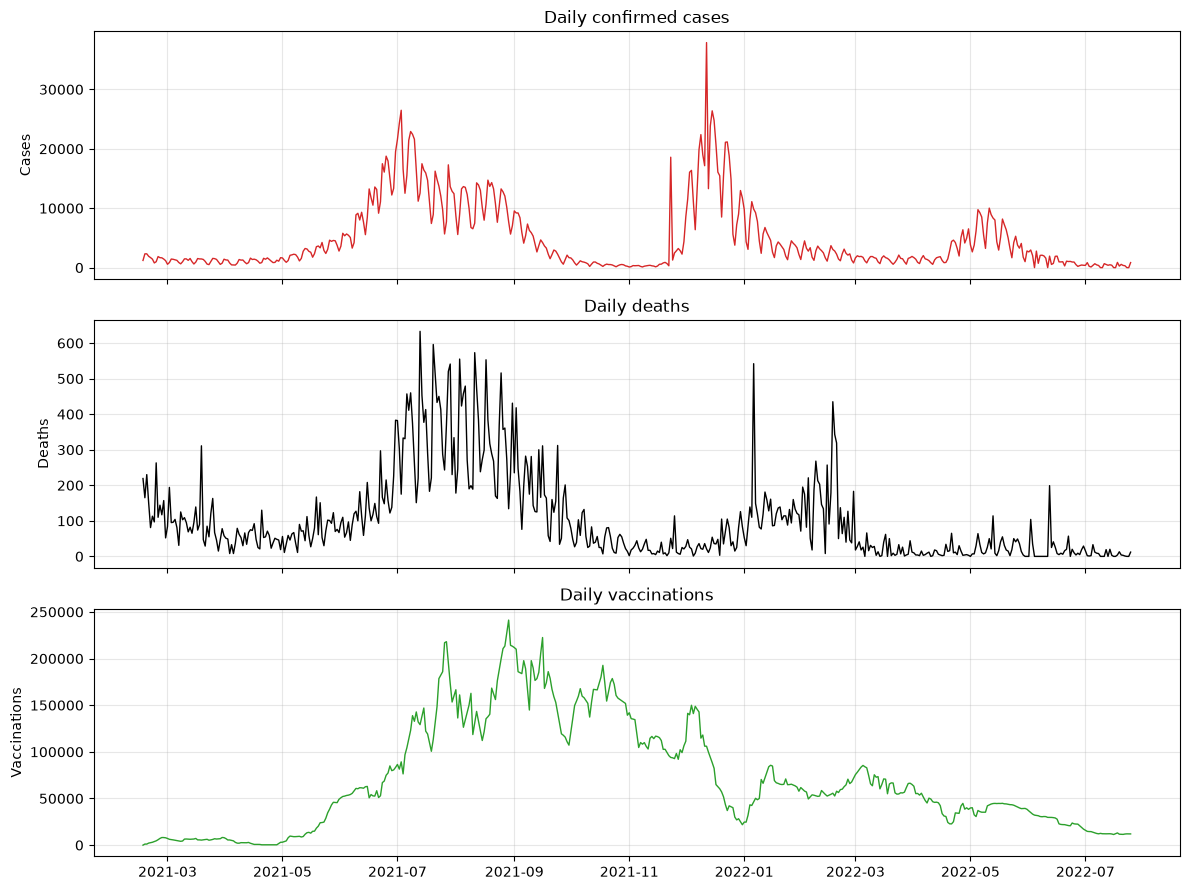

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

axes[0].plot(df["date"], df["daily_cases"], color="tab:red", linewidth=1)
axes[0].set_title("Daily confirmed cases")
axes[0].set_ylabel("Cases")
axes[0].grid(True, alpha=0.3)

axes[1].plot(df["date"], df["daily_deaths"], color="black", linewidth=1)
axes[1].set_title("Daily deaths")
axes[1].set_ylabel("Deaths")
axes[1].grid(True, alpha=0.3)

axes[2].plot(df["date"], df["daily_vaccinations"], color="tab:green", linewidth=1)
axes[2].set_title("Daily vaccinations")
axes[2].set_ylabel("Vaccinations")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
# Save the version that includes daily deaths
df.to_csv("../data/processed/south_africa_cases_vaccination_cleaned.csv", index=False)
print("Saved updated file with daily_deaths included.")
print("Final columns:", df.columns.tolist())
print("Date range:", df["date"].min().date(), "→", df["date"].max().date())

Saved updated file with daily_deaths included.
Final columns: ['date', 'total', 'daily_cases', 'people_vaccinated', 'people_fully_vaccinated', 'total_vaccinations', 'daily_vaccinations', 'population', 'full_vax_coverage', 'partial_vax_coverage', 'N', 'V_approx', 'cumulative_confirmed', 'daily_confirmed', 'recovered_approx', 'daily_deaths', 'total_deaths']
Date range: 2021-02-16 → 2022-07-25
